# Implementation and Time Analysis of Prim's Algorithm (Minimum Spanning Tree)

**Problem:** Given a connected, undirected, **weighted** graph, find a
**Minimum Spanning Tree (MST)** — a subset of edges that connects all vertices,
contains no cycles, and has the **minimum possible total edge weight**.

**Prim's Algorithm (greedy):**
1. Start from any vertex and mark it as part of the MST.
2. Among all edges connecting a vertex *inside* the MST to a vertex *outside* it, pick the one with the **smallest weight**.
3. Add that edge (and the new vertex) to the MST.
4. Repeat until all vertices are included.

This notebook covers:
- Graph representation (adjacency list with weights)
- Prim's algorithm using a **min-heap (priority queue)** — `O(E log V)`
- Prim's algorithm using a simple **array scan** — `O(V^2)`
- User input (enter your own weighted edges)
- Runtime measurement, time complexity, and space complexity
- Visualization of the graph with the MST highlighted
- Verification against `networkx`'s built-in MST
- A runtime comparison of both implementations on sparse and dense graphs


In [1]:
# Common imports used throughout the notebook
import time
import heapq
import random
from collections import defaultdict
import matplotlib.pyplot as plt
import networkx as nx


class WeightedGraph:
    """Undirected weighted graph stored as an adjacency list."""

    def __init__(self):
        self.adj = defaultdict(list)   # node -> list of (neighbor, weight)

    def add_edge(self, u, v, w):
        self.adj[u].append((v, w))
        self.adj[v].append((u, w))

    def nodes(self):
        return list(self.adj.keys())

    def edges(self):
        seen = set()
        result = []
        for u in self.adj:
            for v, w in self.adj[u]:
                key = frozenset((u, v))
                if key not in seen:
                    seen.add(key)
                    result.append((u, v, w))
        return result


In [2]:
def get_user_edges(demo_string=None):
    """Takes weighted edges as 'u,v,w' triples separated by semicolons.

    Example: A,B,4;A,C,3;B,C,1   -> edges A-B (4), A-C (3), B-C (1)

    - Interactive use: call get_user_edges() with NO arguments to be prompted.
    - Notebook demo cells pass a fixed string so the notebook runs end-to-end
      with baked-in outputs. Remove the argument to type your own graph.
    """
    raw = demo_string if demo_string is not None else input(
        "Enter edges as u,v,weight separated by semicolons (e.g., A,B,4;A,C,3;B,C,1): "
    )
    edges = []
    try:
        for triple in raw.split(';'):
            triple = triple.strip()
            if not triple:
                continue
            u, v, w = [x.strip() for x in triple.split(',')]
            edges.append((u, v, int(w)))
        if not edges:
            raise ValueError
    except ValueError:
        print("Invalid input detected, using a default sample graph instead.")
        edges = [('A', 'B', 4), ('A', 'C', 3), ('B', 'C', 1), ('B', 'D', 2),
                 ('C', 'D', 4), ('D', 'E', 2), ('C', 'E', 5)]
    return edges


def build_graph(edges):
    g = WeightedGraph()
    for u, v, w in edges:
        g.add_edge(u, v, w)
    return g


def get_user_start_node(nodes, demo_value=None):
    """Takes the vertex to start Prim's algorithm from."""
    raw = demo_value if demo_value is not None else input(f"Enter the starting node {nodes}: ")
    raw = raw.strip()
    if raw not in nodes:
        print(f"'{raw}' not found in graph nodes, defaulting to '{nodes[0]}'.")
        raw = nodes[0]
    return raw


## 1. Prim's Algorithm using a Min-Heap (Priority Queue)

We keep a min-heap of candidate edges `(weight, from_node, to_node)` that lead
out of the current tree. Each step pops the cheapest candidate; if its target
is not yet in the MST, we add it and push all of the new vertex's edges onto
the heap. Stale entries (whose target was already added through a cheaper edge)
are simply skipped when popped.


In [3]:
def prim_heap(graph, start):
    visited = {start}
    mst_edges = []
    total_weight = 0

    # heap entries: (weight, from_node, to_node)
    heap = [(w, start, v) for v, w in graph.adj[start]]
    heapq.heapify(heap)

    num_nodes = len(graph.adj)

    while heap and len(visited) < num_nodes:
        w, u, v = heapq.heappop(heap)
        if v in visited:
            continue   # stale edge: v already joined the tree
        visited.add(v)
        mst_edges.append((u, v, w))
        total_weight += w

        for nxt, nw in graph.adj[v]:
            if nxt not in visited:
                heapq.heappush(heap, (nw, v, nxt))

    return mst_edges, total_weight


In [4]:
# --- Prim's (heap): User Input + Runtime ---
# Replace the arguments below with nothing, i.e. get_user_edges() / get_user_start_node(nodes),
# to build your own graph and pick your own start node interactively.
edges = get_user_edges("A,B,4;A,C,3;B,C,1;B,D,2;C,D,4;D,E,2;C,E,5")
graph = build_graph(edges)
nodes = graph.nodes()
start = get_user_start_node(nodes, "A")

print("Graph edges (u, v, weight):")
for e in edges:
    print("  ", e)
print("Start node:", start)

t0 = time.time()
mst_edges, total_weight = prim_heap(graph, start)
t1 = time.time()

print("\nMST edges chosen by Prim's (in the order they were added):")
for u, v, w in mst_edges:
    print(f"  {u} - {v}  (weight {w})")
print(f"\nTotal MST weight : {total_weight}")
print(f"Runtime          : {(t1 - t0) * 1000:.4f} ms")


Graph edges (u, v, weight):
   ('A', 'B', 4)
   ('A', 'C', 3)
   ('B', 'C', 1)
   ('B', 'D', 2)
   ('C', 'D', 4)
   ('D', 'E', 2)
   ('C', 'E', 5)
Start node: A

MST edges chosen by Prim's (in the order they were added):
  A - C  (weight 3)
  C - B  (weight 1)
  B - D  (weight 2)
  D - E  (weight 2)

Total MST weight : 8
Runtime          : 0.0408 ms


**Time Complexity:** `O(E log V)` — each edge can be pushed onto the heap at
most twice (once per endpoint), and each heap push/pop costs `O(log E) = O(log V)`.

**Space Complexity:** `O(V + E)` — for the adjacency list, the `visited` set,
and the heap (which can hold up to `O(E)` entries).


## 2. Prim's Algorithm using a Simple Array Scan (`O(V^2)`)

Instead of a heap, keep a `key[v]` array holding the cheapest known edge weight
connecting each outside vertex `v` to the tree. Each iteration scans **all**
vertices linearly to find the unvisited one with the smallest `key`, adds it,
and relaxes the keys of its neighbors. This is simpler, and actually better for
**dense graphs** (where `E` is close to `V^2`).


In [5]:
def prim_array(graph, start):
    INF = float('inf')
    nodes = graph.nodes()
    key = {v: INF for v in nodes}
    parent = {v: None for v in nodes}
    in_mst = {v: False for v in nodes}
    key[start] = 0

    mst_edges = []
    total_weight = 0

    for _ in range(len(nodes)):
        # linear scan to find the cheapest vertex not yet in the MST
        u = None
        best = INF
        for v in nodes:
            if not in_mst[v] and key[v] < best:
                best = key[v]
                u = v
        if u is None:
            break   # graph is disconnected

        in_mst[u] = True
        if parent[u] is not None:
            mst_edges.append((parent[u], u, key[u]))
            total_weight += key[u]

        for v, w in graph.adj[u]:
            if not in_mst[v] and w < key[v]:
                key[v] = w
                parent[v] = u

    return mst_edges, total_weight


In [6]:
# --- Prim's (array scan): same graph, compare against the heap version ---
t0 = time.time()
mst_edges_arr, total_weight_arr = prim_array(graph, start)
t1 = time.time()

print("MST edges chosen by Prim's (array version):")
for u, v, w in mst_edges_arr:
    print(f"  {u} - {v}  (weight {w})")
print(f"\nTotal MST weight : {total_weight_arr}")
print(f"Runtime          : {(t1 - t0) * 1000:.4f} ms")
print(f"\nHeap and array versions agree on total weight: {total_weight == total_weight_arr}")


MST edges chosen by Prim's (array version):
  A - C  (weight 3)
  C - B  (weight 1)
  B - D  (weight 2)
  D - E  (weight 2)

Total MST weight : 8
Runtime          : 0.0627 ms

Heap and array versions agree on total weight: True


**Time Complexity:** `O(V^2)` — the outer loop runs `V` times, and each
iteration does an `O(V)` scan to find the minimum key plus an `O(deg)` neighbor
update (summing to `O(E)` overall, dominated by the `V^2` scans).

**Space Complexity:** `O(V)` extra — for the `key`, `parent`, and `in_mst` arrays
(plus the graph itself).


## 3. Visualizing the Graph and its Minimum Spanning Tree

Edges chosen for the MST are drawn thick and in red; all other edges are thin
and gray. Edge labels show weights.


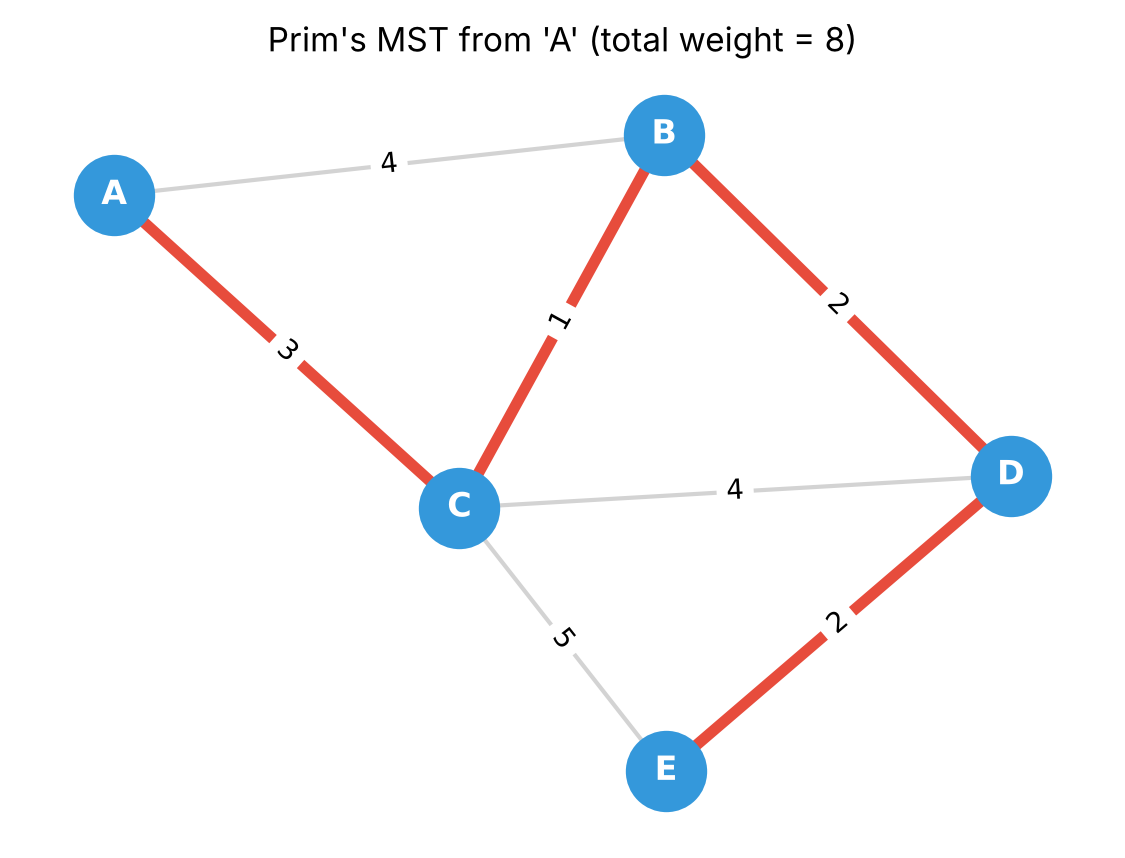

In [7]:
def draw_mst(edges, mst_edges, title):
    G = nx.Graph()
    for u, v, w in edges:
        G.add_edge(u, v, weight=w)

    pos = nx.spring_layout(G, seed=7)
    mst_set = {frozenset((u, v)) for u, v, _ in mst_edges}
    mst_list = [(u, v) for u, v in G.edges() if frozenset((u, v)) in mst_set]
    other_list = [(u, v) for u, v in G.edges() if frozenset((u, v)) not in mst_set]

    fig, ax = plt.subplots(figsize=(7, 5))
    nx.draw_networkx_nodes(G, pos, node_color='#3498db', node_size=800, ax=ax)
    nx.draw_networkx_labels(G, pos, font_color='white', font_weight='bold', ax=ax)
    nx.draw_networkx_edges(G, pos, edgelist=other_list, edge_color='lightgray', width=1.5, ax=ax)
    nx.draw_networkx_edges(G, pos, edgelist=mst_list, edge_color='#e74c3c', width=4, ax=ax)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, 'weight'), ax=ax)
    ax.set_title(title)
    ax.axis('off')
    plt.show()


draw_mst(edges, mst_edges, f"Prim's MST from '{start}' (total weight = {total_weight})")


## 4. Verification against `networkx`

We check our result against `networkx`'s built-in minimum spanning tree. The
MST's **total weight** is unique even if several different trees tie for the
minimum, so that is what we compare (the exact edge set could legitimately
differ when weights tie).


In [8]:
G_nx = nx.Graph()
for u, v, w in edges:
    G_nx.add_edge(u, v, weight=w)

nx_mst = nx.minimum_spanning_tree(G_nx, algorithm='prim')
nx_total = sum(d['weight'] for _, _, d in nx_mst.edges(data=True))

print(f"Our Prim's (heap) total weight  : {total_weight}")
print(f"Our Prim's (array) total weight : {total_weight_arr}")
print(f"networkx MST total weight       : {nx_total}")
print("All match!" if total_weight == total_weight_arr == nx_total else "MISMATCH!")
print(f"\nMST has {len(mst_edges)} edges for {len(nodes)} vertices (always V - 1 = {len(nodes) - 1})")


Our Prim's (heap) total weight  : 8
Our Prim's (array) total weight : 8
networkx MST total weight       : 8
All match!

MST has 4 edges for 5 vertices (always V - 1 = 4)


## 5. Runtime Comparison: Heap-based vs Array-based Prim's

Heap-based Prim's is `O(E log V)` and array-based is `O(V^2)`. The cell below
times both on random connected graphs:
- **Sparse graphs** (`E ~ 3V`): the heap version should win
- **Dense graphs** (`E ~ V^2 / 4`): the gap narrows, since `E log V` approaches `V^2 log V`


In [9]:
random.seed(42)

def random_connected_graph(num_nodes, num_edges):
    g = WeightedGraph()
    # random spanning path first, so the graph is guaranteed connected
    order = list(range(num_nodes))
    random.shuffle(order)
    used = set()
    for a, b in zip(order, order[1:]):
        g.add_edge(a, b, random.randint(1, 100))
        used.add(frozenset((a, b)))
    attempts = 0
    while len(used) < num_edges and attempts < num_edges * 10:
        a, b = random.sample(range(num_nodes), 2)
        key = frozenset((a, b))
        if key not in used:
            used.add(key)
            g.add_edge(a, b, random.randint(1, 100))
        attempts += 1
    return g

def time_both(g):
    t0 = time.time(); _, w1 = prim_heap(g, 0);  heap_t = (time.time() - t0) * 1000
    t0 = time.time(); _, w2 = prim_array(g, 0); arr_t = (time.time() - t0) * 1000
    assert w1 == w2, "Heap and array versions disagree!"
    return heap_t, arr_t

sizes = [100, 200, 400, 800]

sparse_heap, sparse_arr = [], []
dense_heap, dense_arr = [], []

for n in sizes:
    h, a = time_both(random_connected_graph(n, 3 * n))
    sparse_heap.append(h); sparse_arr.append(a)

    h, a = time_both(random_connected_graph(n, n * n // 4))
    dense_heap.append(h); dense_arr.append(a)

print("SPARSE graphs (E ~ 3V)")
print(f"{'V':<8}{'Heap (ms)':<14}{'Array (ms)':<14}")
for n, h, a in zip(sizes, sparse_heap, sparse_arr):
    print(f"{n:<8}{h:<14.4f}{a:<14.4f}")

print("\nDENSE graphs (E ~ V^2 / 4)")
print(f"{'V':<8}{'Heap (ms)':<14}{'Array (ms)':<14}")
for n, h, a in zip(sizes, dense_heap, dense_arr):
    print(f"{n:<8}{h:<14.4f}{a:<14.4f}")


SPARSE graphs (E ~ 3V)
V       Heap (ms)     Array (ms)    
100     0.1292        0.4508        
200     0.2458        1.2982        
400     0.7589        6.3679        
800     2.8377        31.8563       

DENSE graphs (E ~ V^2 / 4)
V       Heap (ms)     Array (ms)    
100     0.5398        0.5407        
200     2.5773        2.0516        
400     16.9916       12.4516       
800     91.2588       59.7963       


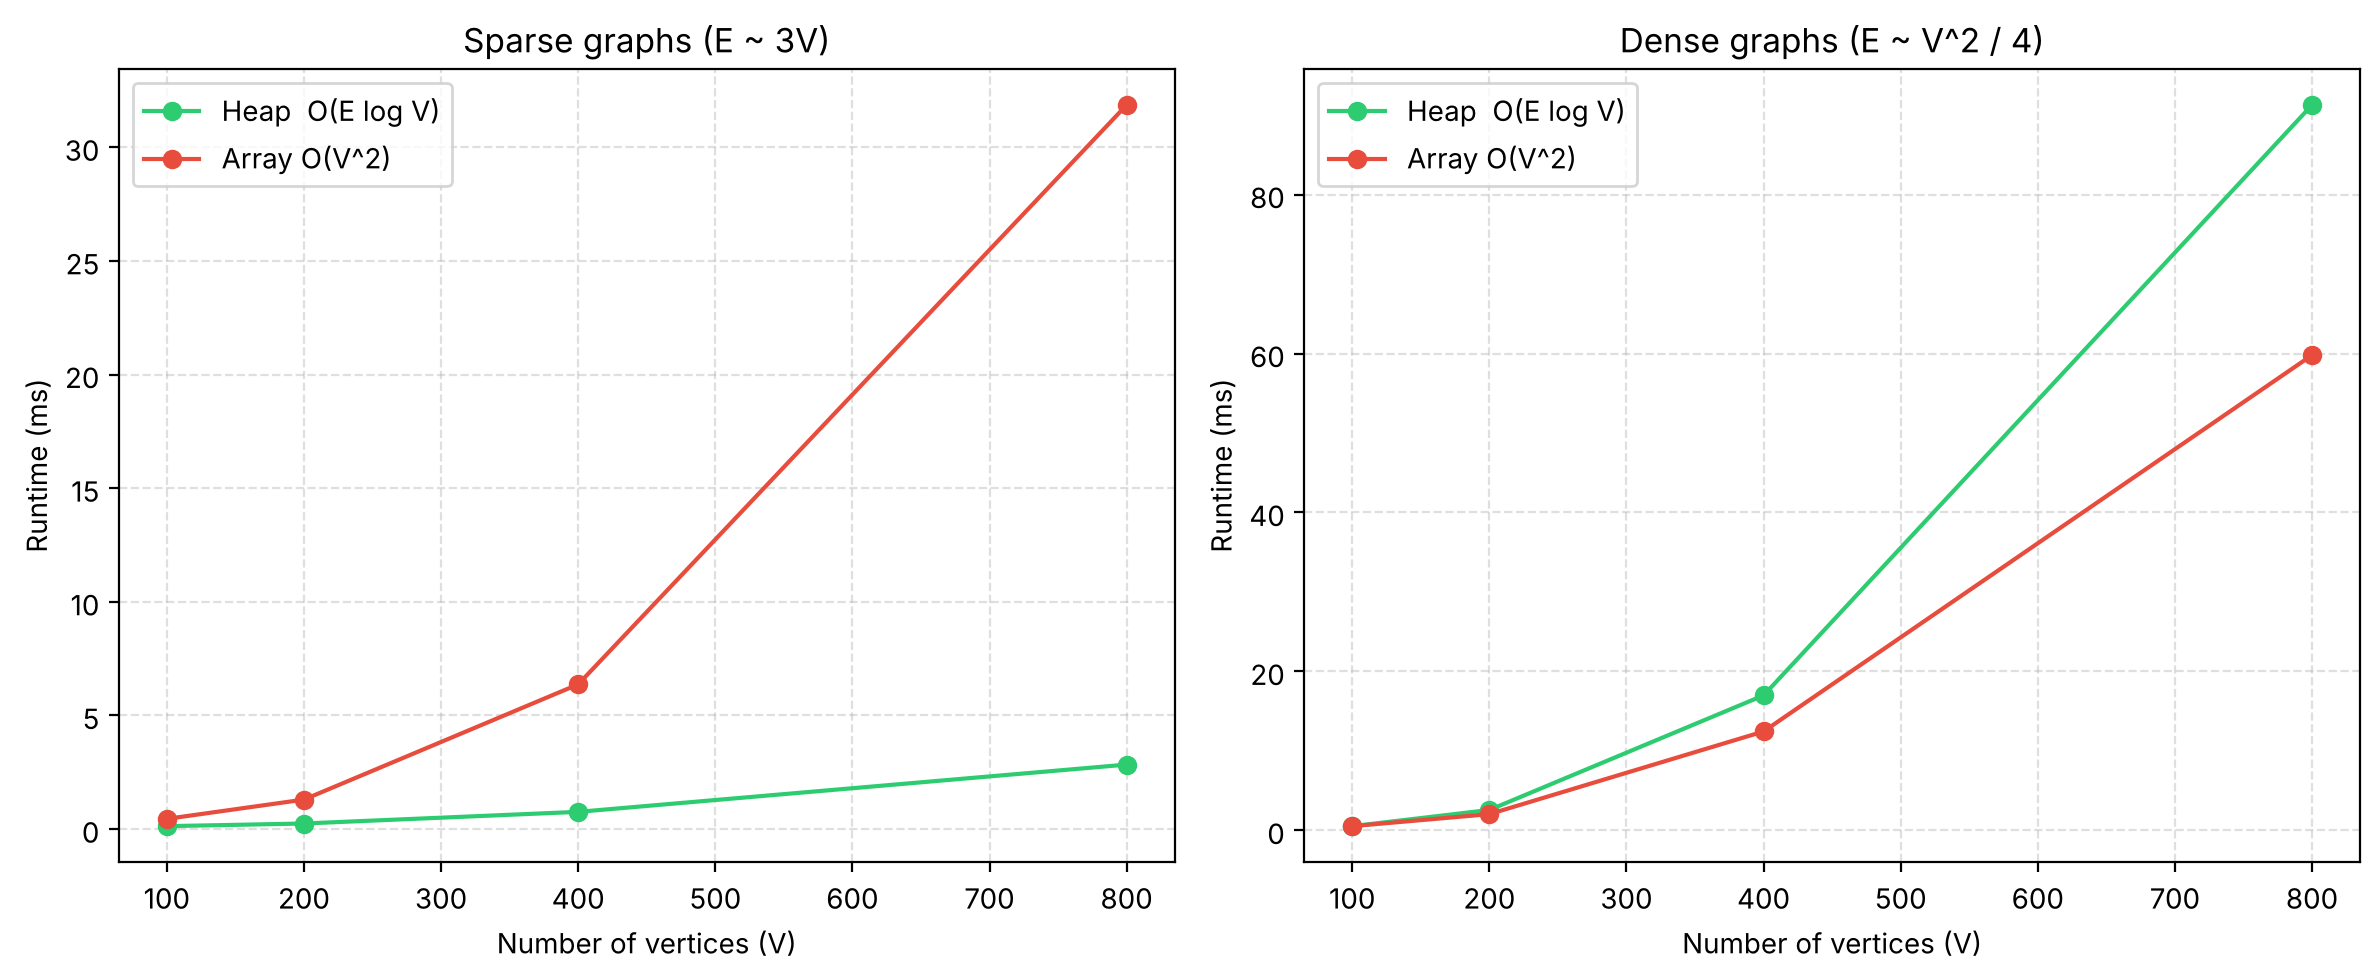

In [10]:
# --- Side-by-side charts: sparse vs dense ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(sizes, sparse_heap, marker='o', label='Heap  O(E log V)', color='#2ecc71')
axes[0].plot(sizes, sparse_arr, marker='o', label='Array O(V^2)', color='#e74c3c')
axes[0].set_title("Sparse graphs (E ~ 3V)")

axes[1].plot(sizes, dense_heap, marker='o', label='Heap  O(E log V)', color='#2ecc71')
axes[1].plot(sizes, dense_arr, marker='o', label='Array O(V^2)', color='#e74c3c')
axes[1].set_title("Dense graphs (E ~ V^2 / 4)")

for ax in axes:
    ax.set_xlabel("Number of vertices (V)")
    ax.set_ylabel("Runtime (ms)")
    ax.legend()
    ax.grid(True, ls="--", alpha=0.4)

plt.tight_layout()
plt.show()


## Summary Table

| Implementation        | Time Complexity | Space Complexity | Best For                 |
|-------------------------|-------------------|---------------------|----------------------------|
| Prim's with min-heap    | O(E log V)         | O(V + E)             | Sparse graphs              |
| Prim's with array scan  | O(V^2)             | O(V)                 | Dense graphs               |

Where `V` = number of vertices, `E` = number of edges.

**Notes:**
- Prim's is a **greedy** algorithm: at every step it makes the locally cheapest choice (the lightest edge crossing the cut between the tree and the rest of the graph). This is provably optimal for MSTs thanks to the **cut property**.
- The MST of a connected graph with `V` vertices always has exactly `V - 1` edges.
- Prim's **grows a single tree** outward from a start vertex, while **Kruskal's algorithm** sorts all edges and merges separate components using union-find — Kruskal's is often simpler for sparse graphs, Prim's tends to shine on dense graphs.
- If the graph is **disconnected**, Prim's only spans the component containing the start vertex (the result is a minimum spanning *forest* only if you rerun it from each unvisited component).
- If several edges share the same weight, the MST may not be unique, but its **total weight** always is.
